In [3]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:

from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Krishok_AI/"
    "Rice_Classification/rice_classification"
)

print("Dataset exists:", DATASET_DIR.exists())

for folder in ["train", "val", "test", "manifests"]:
    path = DATASET_DIR / folder
    print(folder, ":", path.exists())


Dataset exists: True
train : True
val : True
test : True
manifests : True


In [5]:

from pathlib import Path

for split in ["train", "val", "test"]:

    folder = DATASET_DIR / split

    total = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and
        p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".webp"]
    )

    print(split, ":", total)



train : 6827
val : 1464
test : 1463


In [6]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("GPU not available. Enable GPU runtime.")


PyTorch: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [7]:

!pip install -q ultralytics


In [8]:

import ultralytics

print("Ultralytics Version:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics Version: 8.4.216


In [9]:

from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Krishok_AI/"
    "Rice_Classification/rice_classification"
)

assert DATASET_DIR.exists(), "Dataset path not found!"

for split in ["train", "val", "test"]:
    split_path = DATASET_DIR / split

    print(f"\n{split.upper()}")

    for class_dir in sorted(split_path.iterdir()):
        if class_dir.is_dir():
            images = [
                p for p in class_dir.iterdir()
                if p.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".webp"]
            ]
            print(class_dir.name, len(images))



TRAIN
Blast 927
Brown spot 1524
Healthy 1102
Leaf smut 506
Rice Tungro 1566
Sheath blight 1202

VAL
Blast 200
Brown spot 326
Healthy 236
Leaf smut 108
Rice Tungro 336
Sheath blight 258

TEST
Blast 199
Brown spot 326
Healthy 236
Leaf smut 109
Rice Tungro 336
Sheath blight 257


In [11]:

from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Krishok_AI/"
    "Rice_Classification/rice_classification"
)

for split in ["train", "val", "test"]:

    print(f"\n--- {split.upper()} ---")

    for class_dir in sorted(
        (DATASET_DIR / split).iterdir()
    ):
        if class_dir.is_dir():

            images = [
                p for p in class_dir.rglob("*")
                if p.is_file() and
                p.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".webp"]
            ]

            print(class_dir.name, len(images))

    total = sum(
        1 for p in (DATASET_DIR / split).rglob("*")
        if p.is_file() and
        p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".webp"]
    )

    print("TOTAL:", total)



--- TRAIN ---
Blast 927
Brown spot 1524
Healthy 1102
Leaf smut 506
Rice Tungro 1566
Sheath blight 1202
TOTAL: 6827

--- VAL ---
Blast 200
Brown spot 326
Healthy 236
Leaf smut 108
Rice Tungro 336
Sheath blight 258
TOTAL: 1464

--- TEST ---
Blast 199
Brown spot 326
Healthy 236
Leaf smut 109
Rice Tungro 336
Sheath blight 257
TOTAL: 1463


In [14]:
import shutil
from pathlib import Path

SOURCE = "/content/drive/MyDrive/Krishok_AI/Rice_Classification/rice_classification"
LOCAL = "/content/rice_classification"

# Safely copy dataset to local disk for fast access
print("Copying dataset to local storage (this may take a couple of minutes)...")
shutil.copytree(
    SOURCE,
    LOCAL,
    dirs_exist_ok=True
)

# Verify copied folders
local_path = Path(LOCAL)
print("Local dataset exists:", local_path.exists())
for split in ["train", "val", "test"]:
    split_path = local_path / split
    if split_path.exists():
        total_files = len(list(split_path.rglob("*[pP][nN][gG]"))) + len(list(split_path.rglob("*[jJ][pP][gG]"))) + len(list(split_path.rglob("*[jJ][pP][eE][gG]")))
        print(f"{split}: {total_files} images locally verified")
    else:
        print(f"{split} folder missing!")

Copying dataset to local storage (this may take a couple of minutes)...
Local dataset exists: True
train: 6827 images locally verified
val: 1464 images locally verified
test: 1463 images locally verified


In [13]:
from ultralytics import YOLO
from pathlib import Path

# Point to local dataset directory
LOCAL_DATASET_DIR = "/content/rice_classification"

# Load pretrained YOLO11 classification model
model = YOLO("yolo11n-cls.pt")

# Train using local dataset
results = model.train(
    data=LOCAL_DATASET_DIR,
    epochs=30,
    imgsz=224,
    batch=32,      # We can potentially use a larger batch size on local storage
    device=0,
    patience=8,
    workers=4,      # Increased workers since local disk I/O is much faster
    seed=42,
    project="/content/KrishokAI_results",
    name="YOLO11_Rice_v1_local",
    exist_ok=True,
    plots=True,
    verbose=True
)

print("Training completed successfully on local storage!")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rice_classification, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11_Rice_v1_local, nbs=64, nms=None, opset=None, opti

In [15]:

from pathlib import Path
import shutil

RESULT_DIR = Path(
    "/content/KrishokAI_results/YOLO11_Rice_v1_local"
)

BACKUP_DIR = Path(
    "/content/drive/MyDrive/Krishok_AI/"
    "Experiments/YOLO11_Rice_v1"
)

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Save complete experiment
shutil.copytree(
    RESULT_DIR,
    BACKUP_DIR,
    dirs_exist_ok=True
)

print("Experiment backup completed!")
print("Saved at:", BACKUP_DIR)


Experiment backup completed!
Saved at: /content/drive/MyDrive/Krishok_AI/Experiments/YOLO11_Rice_v1



image 1/1 /content/rice_classification/test/Rice Tungro/Rice Tungro_655.jpg: 224x224 Rice Tungro 1.00, Brown spot 0.00, Blast 0.00, Leaf smut 0.00, Healthy 0.00, 4.4ms
Speed: 11.4ms preprocess, 4.4ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)

--- Top Predictions (Our Fine-Tuned Rice Model) ---
Rice Tungro: 99.97%
Brown spot: 0.02%
Blast: 0.00%
Leaf smut: 0.00%
Healthy: 0.00%


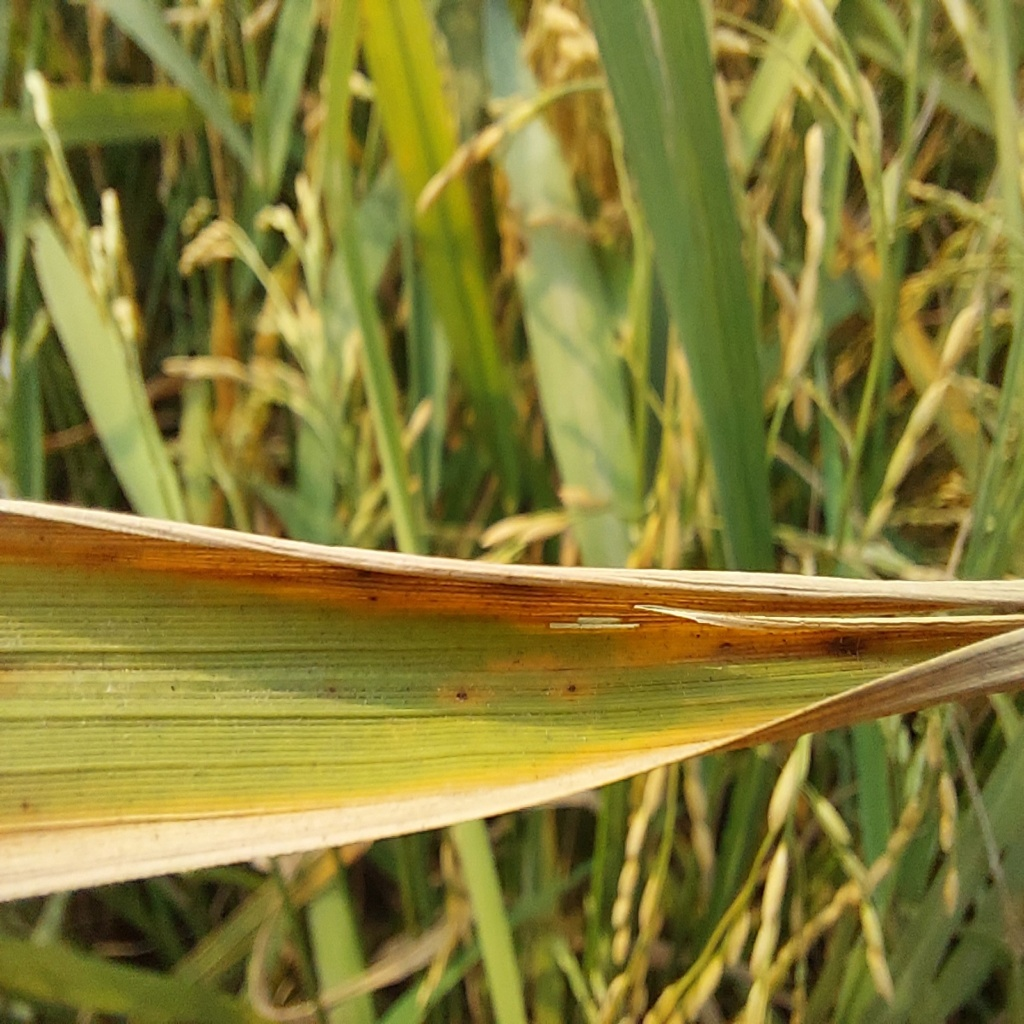

In [19]:
from ultralytics import YOLO
from PIL import Image

# Load our custom trained best model weights
custom_model = YOLO("/content/KrishokAI_results/YOLO11_Rice_v1_local/weights/best.pt")

# Run prediction on the exact same sample image
sample_img_path = "/content/rice_classification/test/Rice Tungro/Rice Tungro_655.jpg"
results = custom_model.predict(sample_img_path)

# Display the top predicted classes from our custom model
for result in results:
    top5_indices = result.probs.top5
    top5_confidences = result.probs.top5conf

    print("\n--- Top Predictions (Our Fine-Tuned Rice Model) ---")
    for idx, conf in zip(top5_indices, top5_confidences):
        class_name = result.names[idx]
        print(f"{class_name}: {conf*100:.2f}%")

# Display the image again
display(Image.open(sample_img_path))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,533,710 parameters, 0 gradients, 3.2 GFLOPs
train: /content/rice_classification/train... found 6827 images in 6/6 classes ✅ 
val: /content/rice_classification/val... found 1464 images in 6/6 classes ✅ 
test: /content/rice_classification/test... found 1463 images in 6/6 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 84.5±30.7 MB/s, size: 333.9 KB)
test: Scanning /content/rice_classification/test... 1463 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1463/1463 371.1it/s 3.9s
test: New cache created: /content/rice_classification/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 92/92 3.6it/s 25.2s
                   all      0.751       0.95
Speed: 0.1ms preprocess, 1.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/KrishokAI_results/YOLO11_Rice_v1_eval

--- Confusion Matrix ---


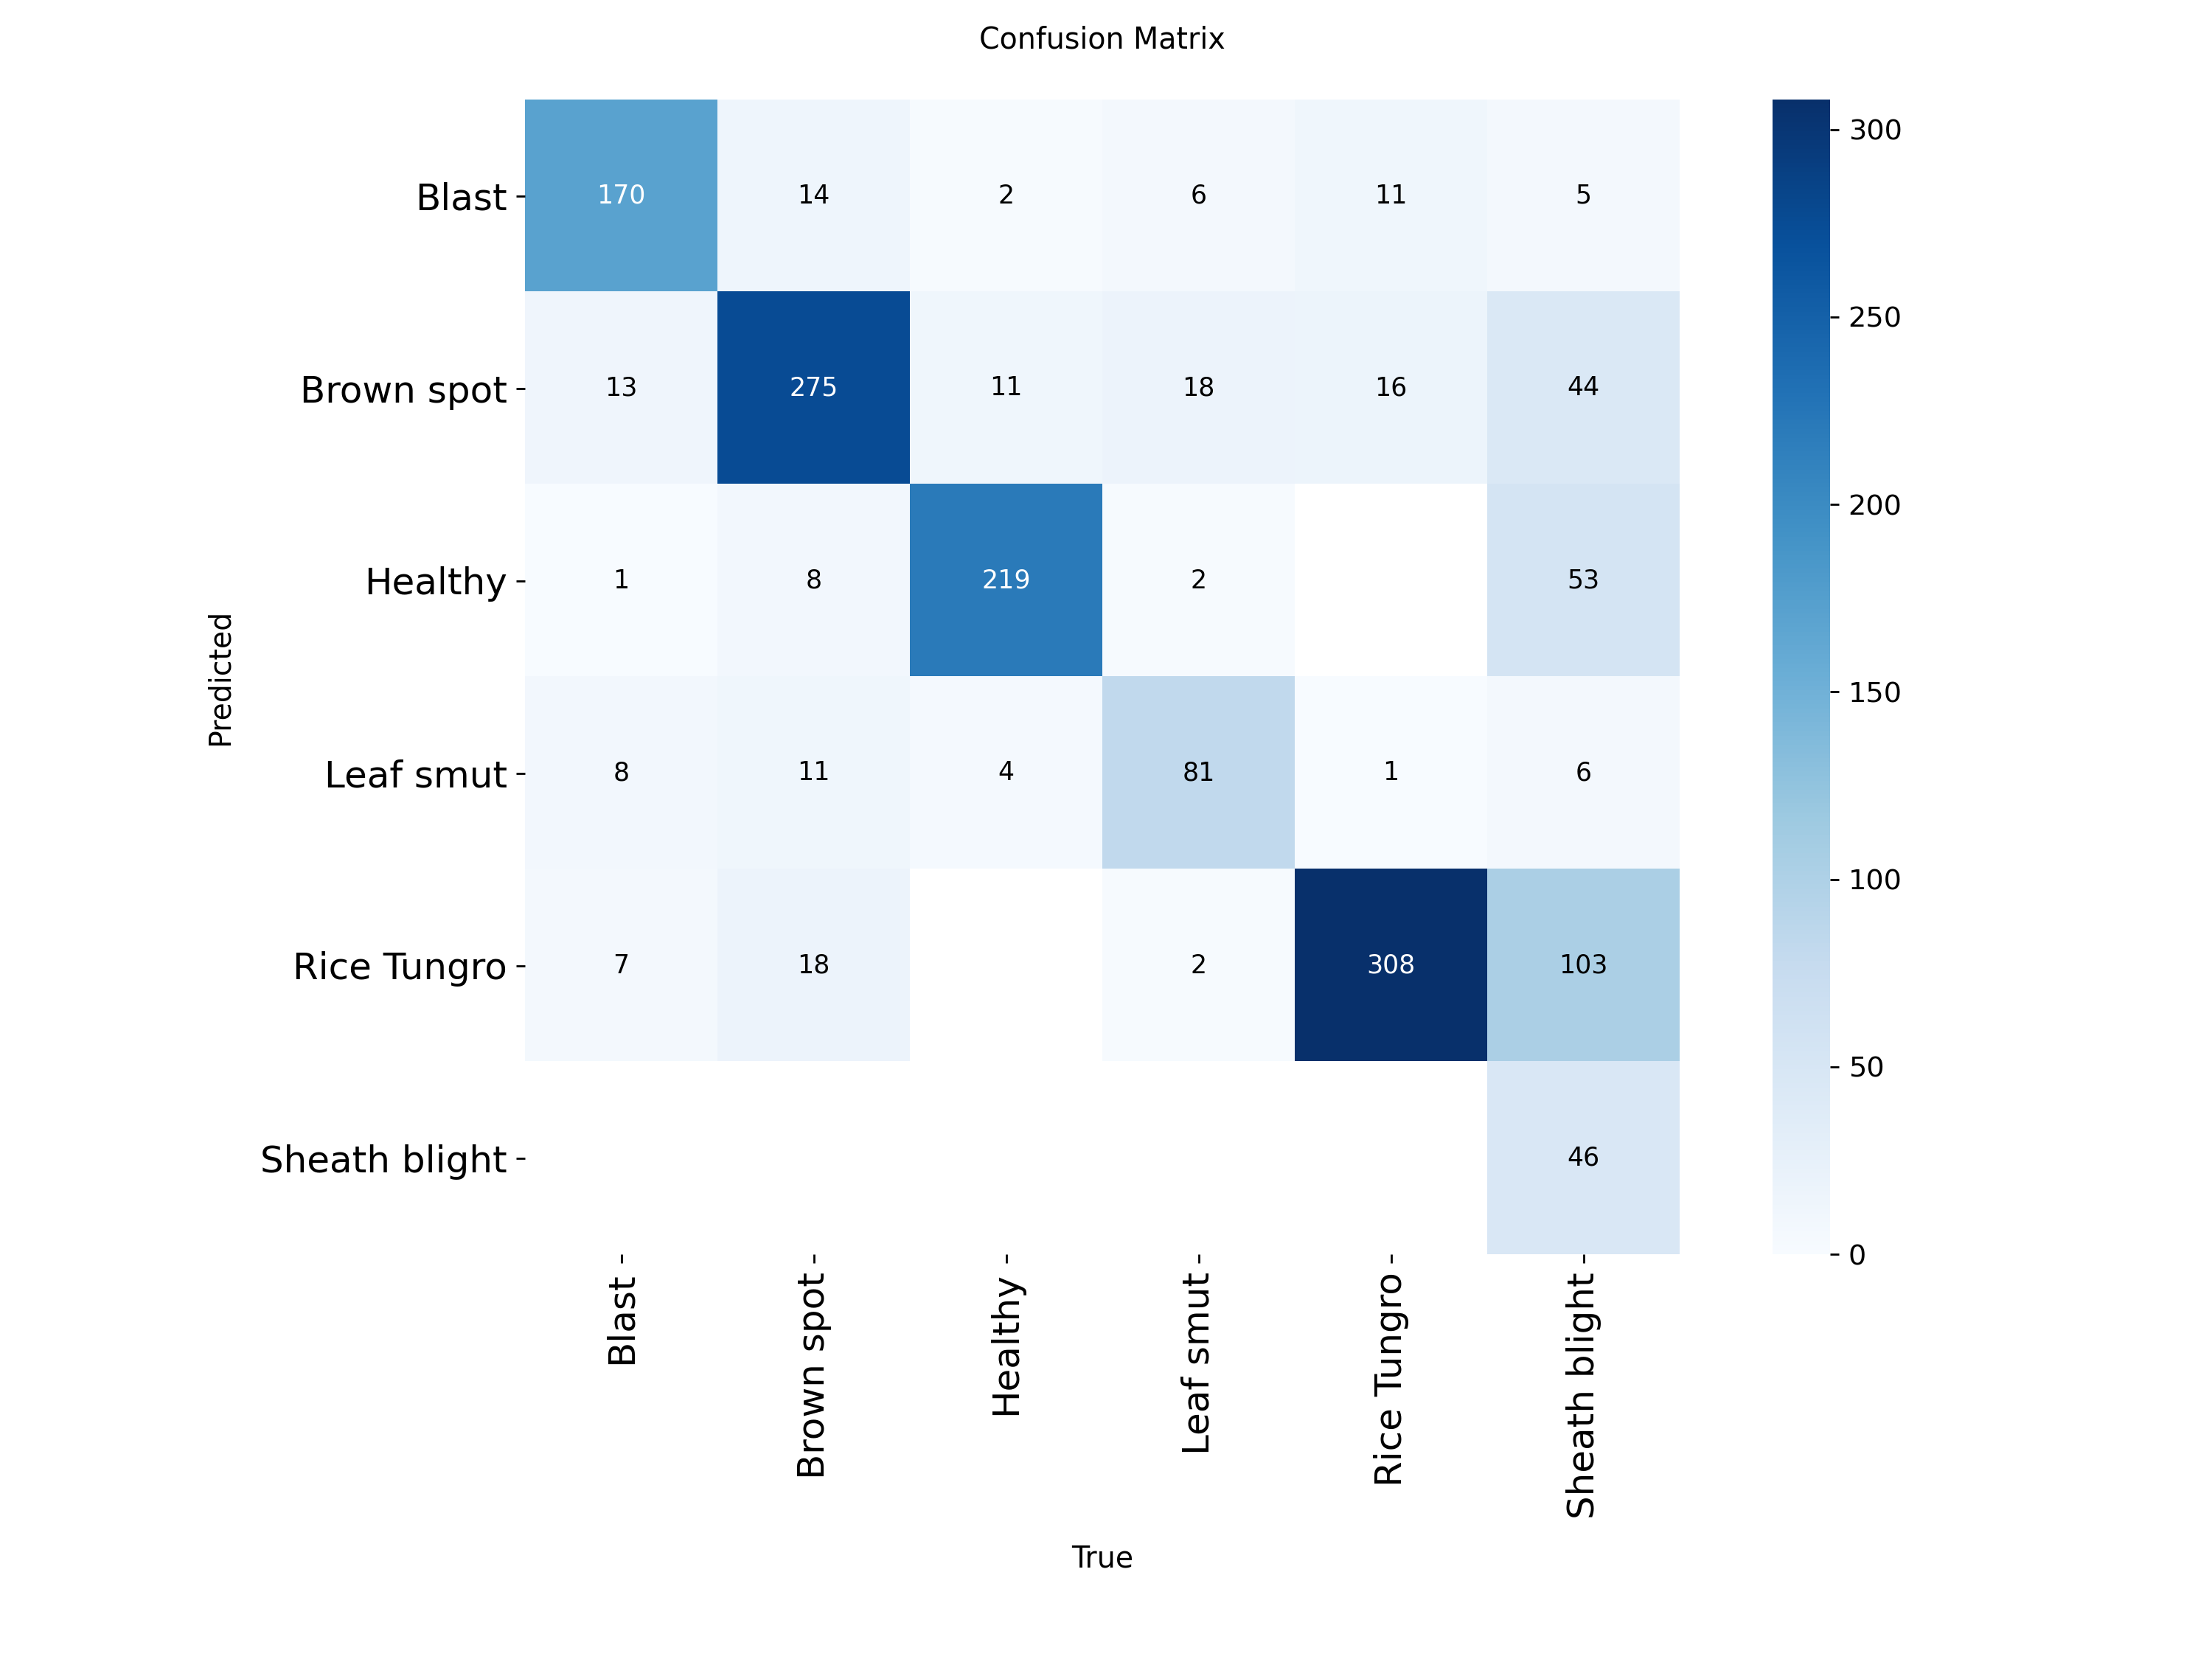

In [20]:
from ultralytics import YOLO
from PIL import Image
from pathlib import Path

# Load our custom trained best model weights
custom_model = YOLO("/content/KrishokAI_results/YOLO11_Rice_v1_local/weights/best.pt")

# Run validation on the test split to compute metrics and generate the confusion matrix
val_results = custom_model.val(
    data="/content/rice_classification",
    split="test",
    project="/content/KrishokAI_results",
    name="YOLO11_Rice_v1_eval",
    exist_ok=True
)

# Define the path to the confusion matrix generated by YOLO
eval_dir = Path("/content/KrishokAI_results/YOLO11_Rice_v1_eval")
confusion_matrix_path = eval_dir / "confusion_matrix.png"

# Display the confusion matrix if it exists
if confusion_matrix_path.exists():
    print("\n--- Confusion Matrix ---")
    display(Image.open(confusion_matrix_path))
else:
    print(f"Confusion matrix image not found at {confusion_matrix_path}. Checking alternative locations...")
    # Sometimes YOLO saves it directly as 'confusion_matrix_normalized.png'
    normalized_cm_path = eval_dir / "confusion_matrix_normalized.png"
    if normalized_cm_path.exists():
        display(Image.open(normalized_cm_path))
    else:
        print("No confusion matrix plot found in the evaluation folder.")